![Banner](../../../../Images/Banner/07_remote_sensing/09_07_banner_rs_texture.png)


# Texture Analysis of Landsat Imagery: Model-Based Methods

Model-based texture methods assume that the image was generated by a spatial stochastic process, fit that model locally, and use the fitted parameters as texture features.


## Overview

A small number of parameters then summarizes the whole neighbourhood: how strongly a pixel depends on its neighbours, how rough the intensity surface is, how much variation the model cannot explain. This notebook covers three model families (Markov Random Fields, fractals and autoregressive models), explains their theory, computes them on the NIR band of a Landsat 9 scene over Las Vegas with `geolattice.rsense.texture`, and tests what they add to spectral information.


### Image texture in brief

Spectral values tell us *what* a pixel is made of; **texture** tells us *how pixel values are arranged*
around it. Texture is the spatial variation of gray levels inside a neighbourhood and describes
properties such as smoothness, coarseness, regularity, directionality and contrast. Haralick,
Shanmugam and Dinstein (1973) noted that tone and texture are always present together in an image, but
one may dominate the other depending on the scene.

At Landsat's 30 m resolution many land-cover classes overlap spectrally: urban fabric, bare soil and
rock are all bright and dry in an arid scene; crop types or forest stands can share the same NDVI;
rough terrain mixes lit slopes and shadow within a few pixels. Texture separates such classes because
it responds to *pattern*, not only to *brightness*, and texture layers are routinely stacked with bands
and indices as predictors in land-cover classification, urban mapping, forest-structure modelling and
soil mapping.

Methods are usually grouped into six families. This series covers them in five notebooks:

| Notebook | Family | Methods |
|---|---|---|
| 09_07_01 | [Statistical and structural texture](09_07_01_texture_analysis_of_landsat_imagery_statistical_and_structural_methods.ipynb) | First-order statistics, GLCM, GLRLM, edge density, lacunarity |
| 09_07_02 | [Transform-based (spectral) texture](09_07_02_texture_analysis_of_landsat_imagery_transform_based_spectral_methods.ipynb) | Fourier power spectrum, Gabor filter bank, Haar wavelets |
| 09_07_03 | [Local pattern-based texture](09_07_03_texture_analysis_of_landsat_imagery_local_pattern_based_methods_lbp.ipynb) | Local Binary Patterns (LBP) |
| 09_07_04 | **Model-based texture** (this notebook) | Markov Random Field energy, fractal dimension, autoregressive model |
| 09_07_05 | [Deep-learning-based texture](09_07_05_texture_analysis_of_landsat_imagery_deep_learning_based_methods.ipynb) | Pretrained CNN feature maps |

All methods come from `geolattice.rsense.texture`. Every function accepts a 2-D `xr.DataArray` (or NumPy
array) and returns a georeferenced result with the same shape as the input; inputs with leading
dimensions (band, time, polarization) are processed slice by slice, and multi-feature methods return an
`xr.Dataset` with one variable per feature.


### Theory 1: Markov Random Fields

A **Markov Random Field** (MRF) models an image as a random field in which the value of a pixel depends
only on its neighbours $\mathcal{N}(s)$ (the Markov property):

$$P\big(g_s \mid g_{S\setminus s}\big) = P\big(g_s \mid g_{\mathcal{N}(s)}\big).$$

The Hammersley-Clifford theorem shows that such a field has a **Gibbs distribution**

$$P(g) = \frac{1}{Z}\exp\!\big(-U(g)/T\big),\qquad U(g) = \sum_{c \in \mathcal{C}} V_c(g),$$

where the energy $U$ is a sum of potentials $V_c$ over **cliques** (sets of mutually neighbouring
pixels) and $Z$ is a normalizing constant (Geman and Geman 1984; Cross and Jain 1983). With pair
cliques and a quadratic potential (a Gaussian MRF, the continuous analogue of the Ising/Potts model)
$V_{\{s,t\}} = \beta\,(g_s - g_t)^2$. A low energy means the configuration is likely under a smoothness
prior; a high energy means neighbours disagree.

Fitting a full MRF (estimating $\beta$ for several neighbour directions) is expensive.
`tx.mrf_texture_energy` uses the clique energy itself as the feature: the mean squared difference
between a pixel and its 4 (first-order) or 8 (second-order) neighbours, averaged over a window. MRFs are
the classic prior in unsupervised segmentation of SAR and optical images, where this energy is the
quantity the segmentation tries to minimize.

### Theory 2: Fractal dimension

Mandelbrot (1982) showed that many natural surfaces are **self-similar**: they look statistically alike
at different magnifications. Pentland (1984) proposed treating an image's intensity as a 3-D surface
$z = g(x, y)$ and measuring its **fractal dimension** $D$. A smooth surface has $D = 2$; the rougher and
more space-filling it is, the closer $D$ gets to 3. For fractional Brownian surfaces $D = 3 - H$, where
$H$ is the Hurst exponent.

**Differential box-counting** (Sarkar and Chaudhuri 1994) estimates $D$ for an $M \times M$ tile. The tile
is split into $r \times r$ grid cells, and the intensity axis is scaled to the same range as the spatial
axis, so it can be divided into boxes of height $r$. In each cell the number of boxes needed to cover the
surface from its minimum $l$ to its maximum $k$ is $n_r = \lceil k/r \rceil - \lfloor l/r \rfloor + 1$.
The total count $N_r = \sum n_r$ follows a power law

$$N_r \propto r^{-D}\quad\Longrightarrow\quad D = \text{slope of } \log N_r \text{ against } \log(1/r).$$

### Theory 3: Autoregressive models

A **simultaneous autoregressive** (SAR) model expresses each pixel as a linear combination of its
neighbours plus noise (Kashyap and Chellappa 1983; Mao and Jain 1992):

$$g_s - \mu = \sum_{t \in \mathcal{N}(s)} \theta_t\,(g_t - \mu) + \varepsilon_s,\qquad \varepsilon_s \sim \mathcal{N}(0, \sigma^2).$$

The coefficients $\theta_t$ describe the strength and direction of spatial dependence, and $\sigma^2$ the
unexplained variation. `tx.autoregressive_texture` fits the isotropic one-parameter version
$g_s \approx \rho\,\bar g_{\mathcal{N}_4}(s)$ in every window by least squares:

$$\hat\rho = \frac{\operatorname{Cov}\big(g, \bar g_{\mathcal{N}_4}\big)}{\operatorname{Var}\big(\bar g_{\mathcal{N}_4}\big)},\qquad
\text{residual} = \frac{\operatorname{Var}\big(g - \hat\rho\,\bar g_{\mathcal{N}_4}\big)}{\operatorname{Var}(g)}.$$

Because the neighbour mean $\bar g_{\mathcal{N}_4}$ averages four pixels, its variance is lower than the
variance of $g$ wherever pixels are only partly correlated, so $\hat\rho$ is often slightly above 1 on
real images. It is best read as a relative measure of spatial coherence; the residual measures how much
of the local variation is *not* explained by the neighbours.


### Applications

| Application | Method | Why it works |
|---|---|---|
| Unsupervised segmentation of SAR and optical images | MRF energy / MRF priors | Smooth regions have low clique energy, boundaries high |
| Speckle and noise characterization | MRF energy, AR residual | Uncorrelated noise breaks neighbour dependence |
| Terrain and surface roughness from DEMs or images | Fractal dimension | Geomorphic surfaces are approximately self-similar |
| Forest canopy structure and disturbance | Fractal dimension, AR coefficients | Gaps and crown size change roughness and correlation |
| Urban morphology | Fractal dimension, MRF energy | Built-up areas are rougher and less coherent than natural cover |
| Sea-ice and oil-slick detection in SAR | MRF segmentation, AR models | Slicks damp waves and change local correlation |
| Geostatistics and spatial statistics | AR models | The same models describe spatial autocorrelation of any variable |


### Learning objectives

1. Explain the Markov property, Gibbs energy and clique potentials of an MRF.
2. Explain fractal dimension and estimate it with differential box-counting, step by step.
3. Explain autoregressive texture models and interpret the coefficient ρ and the residual.
4. Compute MRF energy, fractal dimension and AR texture on Landsat NIR with `geolattice.rsense.texture`, on
   the study window and on the full scene.
5. Compare model-based texture signatures and test what they add to an unsupervised classification.


### Data

| File | Content |
|---|---|
| `data/blue.tif` | Landsat 9 OLI-2 band 2 (blue), Collection 2 Level-2 surface reflectance DN |
| `data/green.tif` | Landsat 9 OLI-2 band 3 (green) |
| `data/red.tif` | Landsat 9 OLI-2 band 4 (red) |
| `data/nir.tif` | Landsat 9 OLI-2 band 5 (NIR) |

All four bands come from the Las Vegas scene used in the Landsat module
([09_02_04_landsat_half_a_century_of_earth_observation](../09_02_optical/09_02_04_landsat_half_a_century_of_earth_observation.ipynb)): path 39, row 35, 8 July 2024, UTM zone
11N (EPSG:32611), 30 m, 1,679 × 1,512 pixels, stored as unsigned 16-bit DN with 0 as the fill value.


### Contents

1. Setup
2. Loading the Landsat bands and the study window
3. Markov Random Field energy
4. Fractal dimension
5. Autoregressive texture
6. Model-based texture of the full scene
7. Application: texture signatures and clustering
8. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup: silence noisy warnings, import the libraries and choose the array backend.
import warnings
warnings.filterwarnings("ignore", category=UserWarning)  # hide routine library warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)  # e.g. 'mean of empty slice' in all-NaN windows
warnings.filterwarnings("ignore", category=FutureWarning)  # deprecation notices from pandas and xarray

import time  # time each texture computation
from pathlib import Path  # portable file paths

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters (DataArray, Dataset)
import rasterio  # GeoTIFF reading and writing
import matplotlib.pyplot as plt  # figures
from matplotlib.patches import Rectangle  # draw the study-window rectangle

import geolattice.rsense as rs  # GeoLattice remote sensing: reading, scaling and plotting
from geolattice.rsense import texture as tx  # GeoLattice texture functions

rasterio.Env(CPL_LOG="/dev/null").__enter__()  # silence GDAL log messages for the whole session
plt.rcParams.update({"figure.dpi": 90})  # figure resolution
# "cpu" keeps every array on NumPy; the texture functions copy GPU arrays to the CPU anyway.
# report the GeoLattice version and switch to the NumPy (CPU) backend
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"))

geolattice.rsense 0.2 (local stand-in) | backend: cpu


## Loading the Landsat bands and the study window

The files hold raw Collection 2 Level-2 digital numbers (DN). We read them with `rs.read`, put them in
one `xr.Dataset`, and convert them to surface reflectance with `rs.optical.scale`, which applies
**reflectance = DN × 0.0000275 − 0.2** and turns the fill value 0 into NaN.

Window-based texture is easier to see, and much faster to compute, on a smaller area. We work on a
512 × 512 pixel window (15.4 × 15.4 km) on the eastern edge of Las Vegas that contains four very
different surfaces:

- the regular **street grid** of the city (west),
- the smooth, bare **alluvial fan** below Frenchman Mountain (centre),
- the folded sedimentary **ridges of Frenchman Mountain** (east),
- the vegetated channel of the **Las Vegas Wash** (south), red in colour infrared.


In [2]:
# 1. Read each band as a 2-D DataArray (drop the singleton "band" dimension).
DATA = Path("../../../../Data/00_shared/data_remote_sensing/landsat9_vegas_20240708/LC09_L2SP_039035_20240708_02_T1")  # Landsat 9 scene, path 39 row 35, 8 July 2024
BANDS = ["blue", "green", "red", "nir"]  # the four bands used in this notebook
# read each band; masked=False keeps the raw digital numbers (DN)
ls_dn = xr.Dataset({b: rs.read(DATA / f"{b}.tif", masked=False).squeeze("band", drop=True)
                    for b in BANDS})  # one variable per band
ls_dn = ls_dn.rio.write_crs(ls_dn["red"].rio.crs)  # store the CRS on the Dataset as a whole

# 2. Scale DN to surface reflectance (fill value 0 becomes NaN) and clip to [1e-4, 1].
# Landsat Collection 2 scale and offset: DN -> reflectance
ls = rs.optical.scale(ls_dn, sensor="landsat").clip(min=1e-4, max=1.0)
# scene size, pixel size and CRS
print(f"{ls.rio.width} x {ls.rio.height} pixels at {ls.rio.resolution()[0]:.0f} m, CRS {ls.rio.crs}")

# 3. Study window (rows/columns in the full scene) and the NIR band used for most texture measures.
WIN = dict(y=slice(500, 1012), x=slice(900, 1412))  # 512 x 512 pixel window (rows 500-1011, columns 900-1411)
sub = ls.isel(WIN)  # all four bands inside the window
nir = sub["nir"]  # the NIR band of the window

1679 x 1512 pixels at 30 m, CRS EPSG:32611


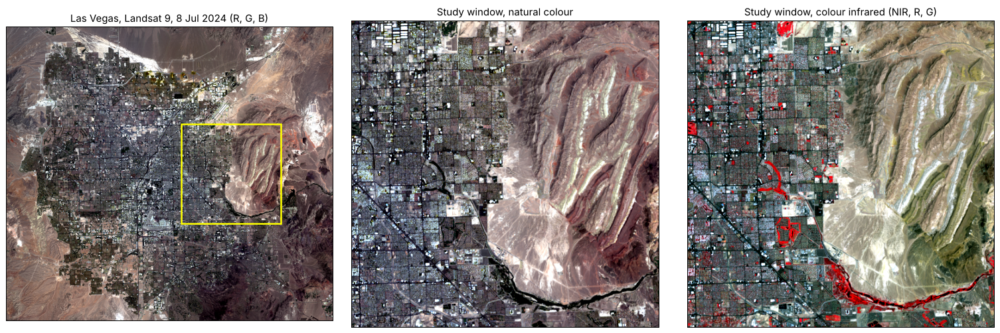

In [3]:
# Where the study window lies, and how it looks in natural colour and colour infrared.
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))  # three panels side by side
# full scene, red-green-blue
rs.viz.plot_rgb(ls, "true_color", ax=axes[0], title="Las Vegas, Landsat 9, 8 Jul 2024 (R, G, B)")
# the study window in yellow (x = column 900, y = row 500)
axes[0].add_patch(Rectangle((900, 500), 512, 512, fill=False, ec="yellow", lw=2))
# the window in natural colour
rs.viz.plot_rgb(sub, "true_color", ax=axes[1], title="Study window, natural colour")
# NIR, red, green: vegetation appears red
rs.viz.plot_rgb(sub, "false_color", ax=axes[2], title="Study window, colour infrared (NIR, R, G)")
for a in axes:  # hide the pixel ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

In [4]:
# three 40 x 40 pixel sample boxes (rows, columns) in the study window
BOXES = {"Urban grid": (slice(100, 140), slice(40, 80)),
         "Alluvial fan": (slice(300, 340), slice(270, 310)),  # gravel slopes
         "Mountain ridges": (slice(130, 170), slice(400, 440))}  # rugged terrain
# one colour per box
COLORS = {"Urban grid": "#d7191c", "Alluvial fan": "#fdae61", "Mountain ridges": "#2b83ba"}

## Markov Random Field energy

### A toy check: smooth vs. noisy fields

Three synthetic fields with the same variance: a smooth (strongly correlated) field, a moderately
correlated field and white noise. The clique energy rises as spatial dependence weakens.


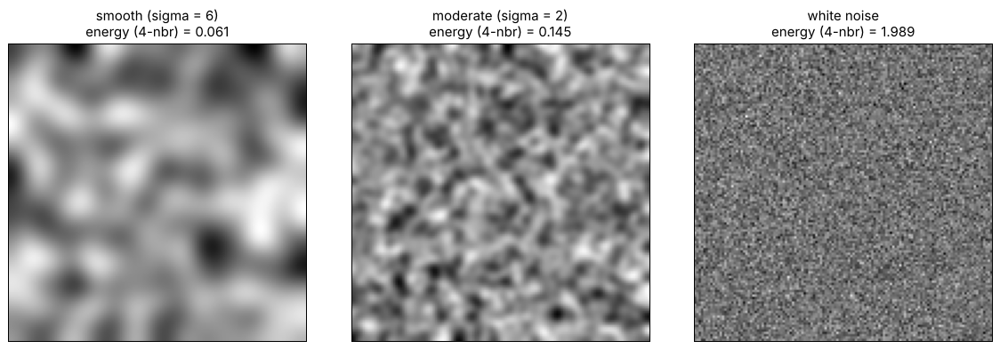

,smooth (sigma = 6),moderate (sigma = 2),white noise
4-neighbour energy,0.061,0.145,1.989
8-neighbour energy,0.091,0.211,1.996


In [5]:
from scipy.ndimage import gaussian_filter  # smoothing
rng = np.random.default_rng(0)  # random generator with a fixed seed
fields = {}  # three synthetic surfaces
# smoothing sigma per surface (0 = none)
for name, s in [("smooth (sigma = 6)", 6), ("moderate (sigma = 2)", 2), ("white noise", 0)]:
    f = rng.normal(size=(128, 128))  # white Gaussian noise
    f = gaussian_filter(f, s) if s else f  # smooth it unless sigma is 0
    fields[name] = (f - f.mean()) / f.std()  # standardise to mean 0, std 1

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))  # three panels
energy = {}  # mean MRF energy per surface
for ax, (name, f) in zip(axes, fields.items()):  # loop over the surfaces
    ax.imshow(f, cmap="gray"); ax.set_xticks([]); ax.set_yticks([])  # show the surface, no ticks
    # mean energy with 4 and 8 neighbours
    energy[name] = {f"{n}-neighbour energy": float(np.mean(tx.mrf_texture_energy(f, size=9, neighborhood=n))) for n in (4, 8)}
    # title with the 4-neighbour energy
    ax.set_title(f"{name}\nenergy (4-nbr) = {energy[name]['4-neighbour energy']:.3f}")
plt.tight_layout(); plt.show()  # arrange and draw
# show the table
pd.DataFrame(energy).round(3)

Energy rises from 0.06 for the smooth field to 0.15 for the moderately correlated field and 1.99 for
white noise.


For unit-variance white noise the expected squared difference between two independent pixels is
2, which is what the 4-neighbour energy returns. Correlated fields have much lower energy.

### MRF energy of the Landsat window

`tx.mrf_texture_energy(img, size, neighborhood)` returns one layer: the mean clique energy in a
`size` × `size` window, with a 4- or 8-pixel neighbourhood.


mrf_texture_energy x2: 0.08 s


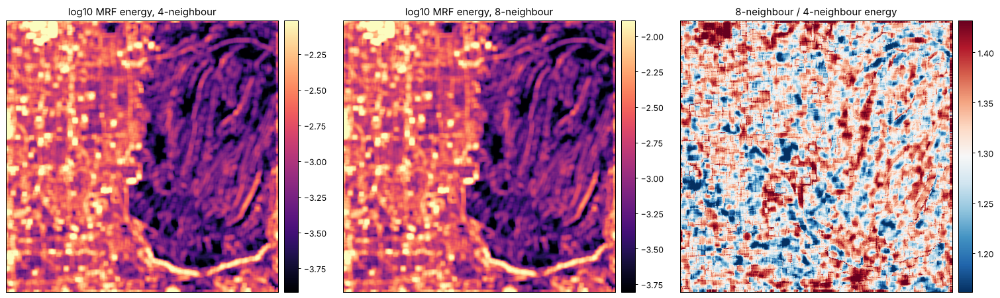

In [6]:
t0 = time.time()  # start the timer
# mean squared difference to the 4 nearest neighbours, in 9 x 9 windows
mrf4 = tx.mrf_texture_energy(nir, size=9, neighborhood=4)
mrf8 = tx.mrf_texture_energy(nir, size=9, neighborhood=8)  # the same with all 8 neighbours
print(f"mrf_texture_energy x2: {time.time() - t0:.2f} s")  # run time

fig, axes = plt.subplots(1, 3, figsize=(17, 5))  # three panels
# log energy, 4 neighbours
rs.viz.plot_raster(np.log10(mrf4), ax=axes[0], cmap="magma", title="log10 MRF energy, 4-neighbour")
# log energy, 8 neighbours
rs.viz.plot_raster(np.log10(mrf8), ax=axes[1], cmap="magma", title="log10 MRF energy, 8-neighbour")
# ratio: how much the diagonal neighbours add
rs.viz.plot_raster(mrf8 / mrf4, ax=axes[2], cmap="RdBu_r", title="8-neighbour / 4-neighbour energy")
for a in axes:  # no ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

MRF energy is about seven times higher in the city than on the fan or the ridges (log10 −2.59 against
−3.44 and −3.43), and the Wash stands out as a high-energy line. The 8/4 ratio lies between 1.28 and 1.33
in all three boxes: at 30 m every surface is spatially correlated, so diagonal neighbours are always less
similar than direct ones.


Diagonal neighbours are √2 farther away than the four direct neighbours. On a spatially correlated
surface they are therefore less similar to the centre, and the 8-neighbour energy is higher than the
4-neighbour energy (a ratio near 1.5 for the smooth toy fields). For independent pixels distance does
not matter and the ratio is 1, as for the white-noise field.


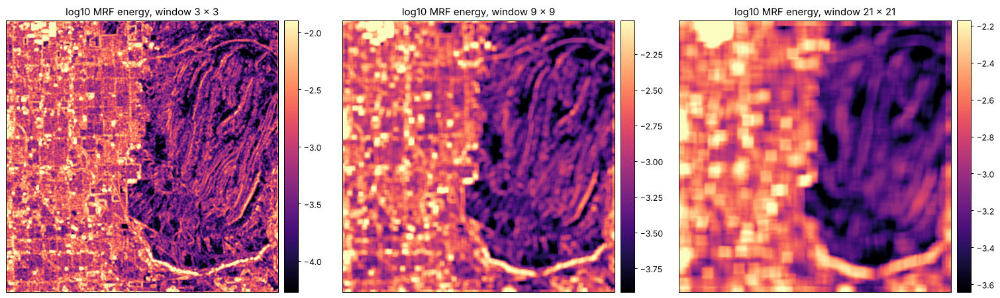

In [7]:
# Effect of the pooling window.
fig, axes = plt.subplots(1, 3, figsize=(17, 5))  # three windows
for ax, s in zip(axes, [3, 9, 21]):  # 3, 9 and 21 pixels
    # log MRF energy in this window
    rs.viz.plot_raster(np.log10(tx.mrf_texture_energy(nir, size=s)), ax=ax, cmap="magma",
                       title=f"log10 MRF energy, window {s} x {s}")
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

A 3 × 3 window maps individual streets and ridge lines; a 21 × 21 window (630 m) maps neighbourhoods. The
window does not change the contrast between surfaces, only the scale at which it is shown.


## Fractal dimension

### Differential box-counting step by step

We implement the box count for one 32 × 32 tile in each sample box and fit the log-log line. This is
the same calculation `tx.fractal_dimension` performs for every tile.


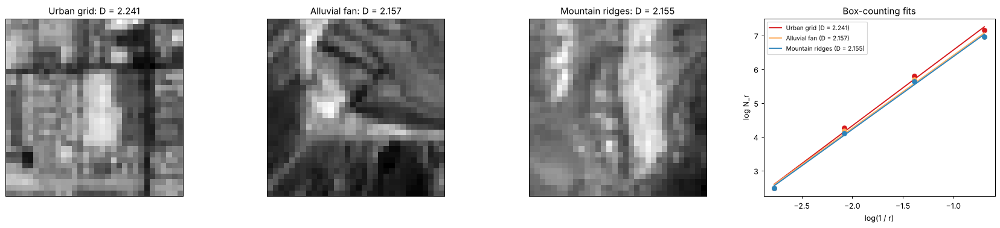

In [8]:
def dbc_counts(tile, box_sizes=(2, 4, 8, 16)):  # differential box counting on a square tile
    """Differential box-counting: total box count N_r for each box size r."""
    size = tile.shape[0]  # tile side in pixels
    t = (tile - tile.min()) / max(tile.max() - tile.min(), 1e-9) * size   # intensity scaled to the grid size
    counts = []  # N_r for each box size
    for r in box_sizes:  # loop over box sizes
        n = size // r  # boxes per side
        cells = t[:n * r, :n * r].reshape(n, r, n, r)  # split the tile into n x n blocks of r x r pixels
        lo, hi = cells.min(axis=(1, 3)), cells.max(axis=(1, 3))  # lowest and highest intensity in each block
        # boxes of height r needed to cover the intensity range of each block, summed
        counts.append(np.sum(np.ceil(hi / r) - np.floor(lo / r) + 1))
    return np.array(counts, float)  # N_r as floats

r = np.array([2, 4, 8, 16])  # box sizes
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))  # three tiles and the fit plot
for k, (name, (ys, xs)) in enumerate(BOXES.items()):  # one tile per sample box
    # the central 32 x 32 pixels of the box
    tile = nir.values[ys.start + 4:ys.start + 36, xs.start + 4:xs.start + 36]
    N = dbc_counts(tile)  # box counts
    D, b = np.polyfit(np.log(1 / r), np.log(N), 1)  # slope of log N_r against log(1/r) = fractal dimension D
    axes[k].imshow(tile, cmap="gray"); axes[k].set_title(f"{name}: D = {D:.3f}")  # the tile with its D
    axes[k].set_xticks([]); axes[k].set_yticks([])  # no ticks
    axes[3].plot(np.log(1 / r), np.log(N), "o", color=COLORS[name])  # the counts
    # the fitted line
    axes[3].plot(np.log(1 / r), D * np.log(1 / r) + b, "-", color=COLORS[name], label=f"{name} (D = {D:.3f})")
axes[3].set(xlabel="log(1 / r)", ylabel="log N_r", title="Box-counting fits")  # labels
axes[3].legend(fontsize=8)  # legend
plt.tight_layout(); plt.show()  # arrange and draw

The log-log points lie almost on straight lines, as the power law predicts. The urban tile is the
roughest (D = 2.24), and the fan and ridge tiles are nearly equal (2.16). The lines are close together:
fractal dimension differences between surfaces are small at this resolution.


In [9]:
# Fractal dimension of synthetic fractional Brownian-like surfaces with known roughness.
def fbm_surface(h, n=256, seed=0):  # a random surface whose roughness is set by h
    """Spectral synthesis of a fractional Brownian surface with Hurst exponent h (D = 3 - h)."""
    rng = np.random.default_rng(seed)  # random generator
    # squared spatial frequency of every FFT cell
    k = np.fft.fftfreq(n)[:, None] ** 2 + np.fft.fftfreq(n)[None, :] ** 2
    k[0, 0] = 1  # avoid dividing by zero at frequency 0
    amp = k ** (-(h + 1) / 2)  # amplitude falls with frequency as a power law
    phase = np.exp(2j * np.pi * rng.random((n, n)))  # random phases
    return np.real(np.fft.ifft2(amp * phase))  # inverse FFT gives the surface

rows = []  # one row per Hurst exponent
for h in [0.2, 0.5, 0.8]:  # rough (0.2) to smooth (0.8)
    s = fbm_surface(h)  # the surface
    fd_s = tx.fractal_dimension(s, size=32, step=16)  # D in 32 x 32 tiles every 16 pixels
    # theoretical vs estimated D
    rows.append({"Hurst H": h, "theoretical D = 3 - H": 3 - h, "estimated D (median)": float(np.nanmedian(fd_s))})
# show the table
pd.DataFrame(rows).round(3)

,Hurst H,theoretical D = 3 - H,estimated D (median)
0,0.2,2.8,2.180
1,0.5,2.5,2.092
2,0.8,2.2,2.027


Box-counting with only four box sizes on 32 × 32 tiles is strongly biased: all three estimates lie
between 2.03 and 2.18, far below the theoretical 2.2 to 2.8. The ranking is still correct, and rougher
surfaces always get a higher estimate. This is how fractal dimension should be used in practice: as a
relative measure of roughness, compared only between estimates made with the same tile and box sizes.

### Fractal dimension map

`tx.fractal_dimension(img, size, step, box_sizes)` estimates D in a `size` × `size` tile every `step`
pixels. All box sizes must divide the tile size evenly.


fractal_dimension x2: 12.9 s
D (32 x 32 tiles), 5th/50th/95th percentile: [2.088 2.162 2.246]


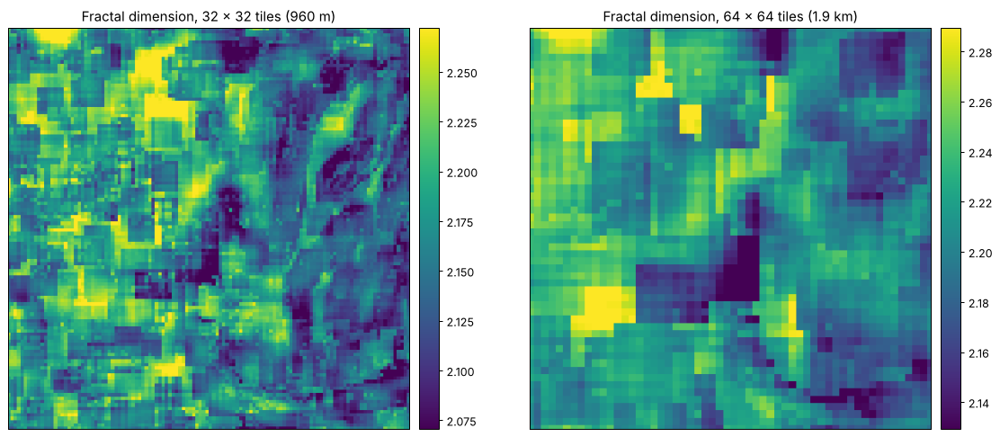

In [10]:
t0 = time.time()  # start the timer
fd = tx.fractal_dimension(nir, size=32, step=4, box_sizes=(2, 4, 8, 16))  # 32 x 32 tiles every 4 pixels
# 64 x 64 tiles every 8 pixels, one more box size
fd64 = tx.fractal_dimension(nir, size=64, step=8, box_sizes=(2, 4, 8, 16, 32))
print(f"fractal_dimension x2: {time.time() - t0:.1f} s")  # run time
# spread of D over the window
print("D (32 x 32 tiles), 5th/50th/95th percentile:", np.round(np.nanpercentile(fd, [5, 50, 95]), 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))  # two panels
# 32-pixel tiles
rs.viz.plot_raster(fd, ax=axes[0], cmap="viridis", title="Fractal dimension, 32 x 32 tiles (960 m)")
# 64-pixel tiles
rs.viz.plot_raster(fd64, ax=axes[1], cmap="viridis", title="Fractal dimension, 64 x 64 tiles (1.9 km)")
for a in axes:  # no ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

D varies between about 2.09 and 2.25. With 64 × 64 tiles the urban box reaches 2.26 against 2.15 on the
fan and 2.17 on the ridges. The maps are blocky because each value describes a whole tile; the city is
generally rougher, but the contrast is weaker than for MRF energy.


## Autoregressive texture

### The model in each sample box

For each box we plot every pixel against the mean of its 4 neighbours and fit the regression line. The
slope is ρ and the scatter around the line is the residual.


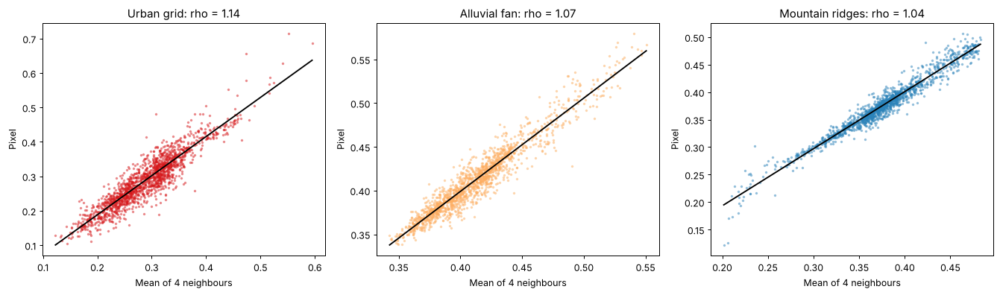

,Urban grid,Alluvial fan,Mountain ridges
rho,1.136,1.067,1.039
residual share,0.151,0.080,0.049
"corr(pixel, nbr mean)",0.922,0.959,0.975


In [11]:
a = nir.fillna(float(nir.mean())).values  # NIR as an array, NaN -> mean
# mean of the four neighbours (np.roll shifts the image by one pixel)
nbr = (np.roll(a, 1, 0) + np.roll(a, -1, 0) + np.roll(a, 1, 1) + np.roll(a, -1, 1)) / 4

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=False)  # one scatter plot per box
rows = {}  # AR parameters per box
for ax, (name, (ys, xs)) in zip(axes, BOXES.items()):  # loop over the boxes
    x_, y_ = nbr[ys, xs].ravel(), a[ys, xs].ravel()  # neighbour mean (x) and pixel value (y)
    rho = np.cov(y_, x_)[0, 1] / np.var(x_, ddof=1)  # least-squares slope: the AR coefficient
    # share of the variance the model does not explain
    resid = np.var((y_ - y_.mean()) - rho * (x_ - x_.mean())) / np.var(y_)
    # store rho, residual share and correlation
    rows[name] = {"rho": rho, "residual share": resid, "corr(pixel, nbr mean)": np.corrcoef(x_, y_)[0, 1]}
    ax.scatter(x_, y_, s=3, alpha=0.4, color=COLORS[name])  # pixel against neighbour mean
    xx = np.linspace(x_.min(), x_.max(), 2)  # two x values to draw the line
    ax.plot(xx, y_.mean() + rho * (xx - x_.mean()), "k-")  # the fitted line
    ax.set(xlabel="Mean of 4 neighbours", ylabel="Pixel", title=f"{name}: rho = {rho:.2f}")  # labels
plt.tight_layout(); plt.show()  # arrange and draw
# show the table
pd.DataFrame(rows).round(3)

The ridges are the most coherent surface: a pixel is almost fully predicted by its neighbours
(correlation 0.975, residual share 5%). The fan follows (0.96, 8%), and the city is the least coherent
(0.92, 15%). ρ is above 1 in all three boxes (1.04 to 1.14), as explained in the theory section.


`tx.autoregressive_texture(img, size)` computes ρ and the residual share in every `size` × `size` window
with box filters (closed form, no loop), so it is fast even on large images.


autoregressive_texture x2: 0.35 s -> ['rho', 'residual']


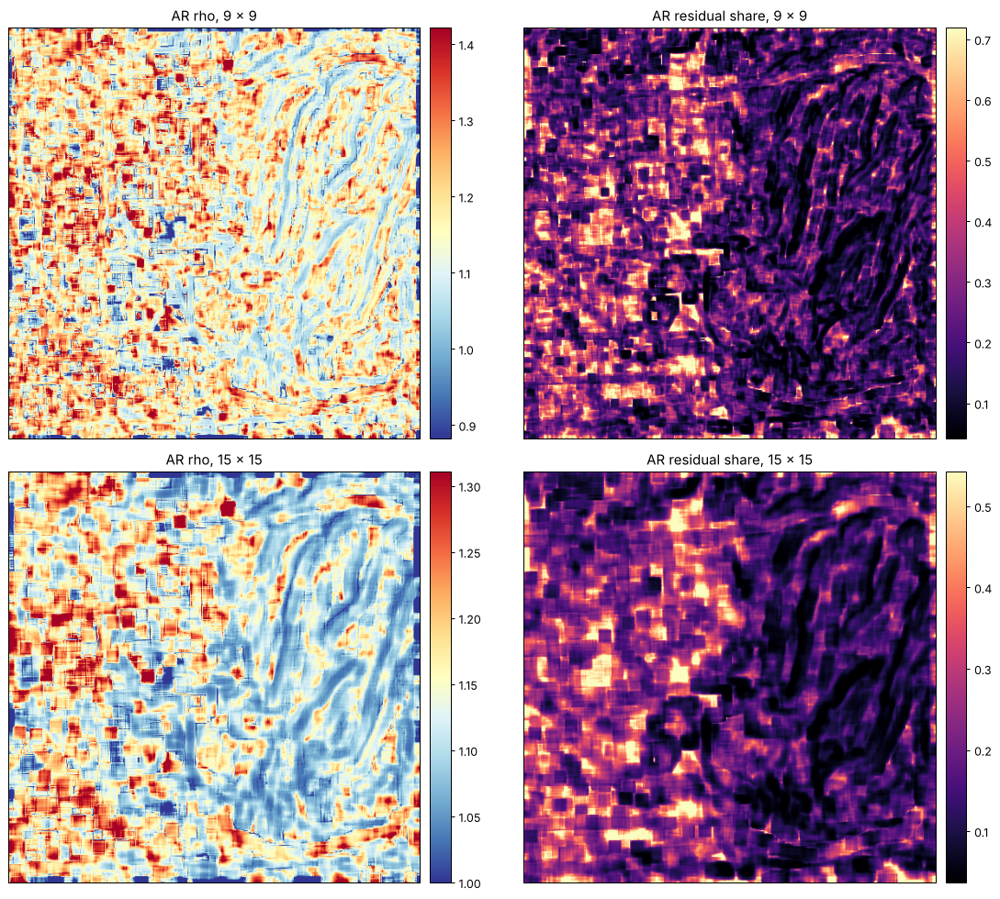

In [12]:
t0 = time.time()  # start the timer
ar = tx.autoregressive_texture(nir, size=9)  # rho and residual share in 9 x 9 windows
ar15 = tx.autoregressive_texture(nir, size=15)  # the same in 15 x 15 windows
print(f"autoregressive_texture x2: {time.time() - t0:.2f} s ->", list(ar.data_vars))  # run time and layer names

fig, axes = plt.subplots(2, 2, figsize=(13, 11))  # 2 x 2 panels
rs.viz.plot_raster(ar["rho"], ax=axes[0, 0], cmap="RdYlBu_r", title="AR rho, 9 x 9")  # rho, 9 x 9
# residual share, 9 x 9
rs.viz.plot_raster(ar["residual"], ax=axes[0, 1], cmap="magma", title="AR residual share, 9 x 9")
rs.viz.plot_raster(ar15["rho"], ax=axes[1, 0], cmap="RdYlBu_r", title="AR rho, 15 x 15")  # rho, 15 x 15
# residual share, 15 x 15
rs.viz.plot_raster(ar15["residual"], ax=axes[1, 1], cmap="magma", title="AR residual share, 15 x 15")
for a_ in axes.ravel():  # no ticks
    a_.set_xticks([]); a_.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

ρ is highest on block-sized city patches and lowest along sharp ridge lines. The residual is high where
the simple model fails: isolated bright roofs, the edges of the Wash and the city blocks. A larger window
(15 × 15) gives smoother, lower residuals, because more pixels average out local surprises.


## Model-based texture of the full scene

MRF energy and the AR model use box filters and run on the whole 1,679 × 1,512 scene in about a second.
Fractal dimension loops over tiles; with 32 × 32 tiles every 8 pixels the full scene takes about
20 seconds.


Full scene, three model-based measures: 23.6 s


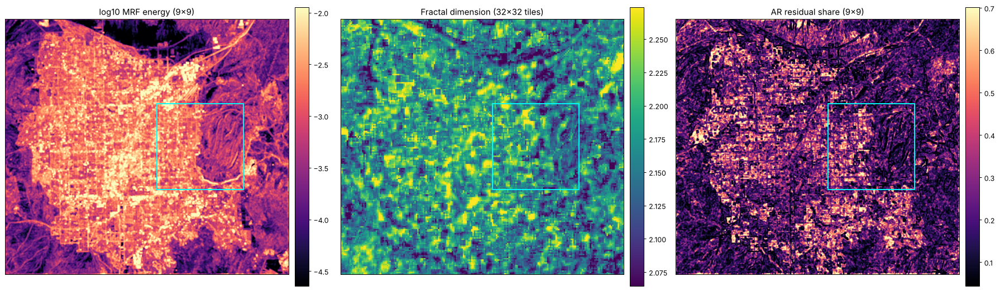

In [13]:
t0 = time.time()  # start the timer
mrf_full = tx.mrf_texture_energy(ls["nir"], size=9)  # MRF energy of the whole scene
fd_full = tx.fractal_dimension(ls["nir"], size=32, step=8)  # fractal dimension of the whole scene
ar_full = tx.autoregressive_texture(ls["nir"], size=9)  # autoregressive texture of the whole scene
print(f"Full scene, three model-based measures: {time.time() - t0:.1f} s")  # run time

fig, axes = plt.subplots(1, 3, figsize=(20, 6))  # three panels
# log MRF energy
rs.viz.plot_raster(np.log10(mrf_full), ax=axes[0], cmap="magma", title="log10 MRF energy (9x9)")
# fractal dimension
rs.viz.plot_raster(fd_full, ax=axes[1], cmap="viridis", title="Fractal dimension (32x32 tiles)")
# AR residual share
rs.viz.plot_raster(ar_full["residual"], ax=axes[2], cmap="magma", title="AR residual share (9x9)")
for a_ in axes:  # for each panel:
    a_.add_patch(Rectangle((900, 500), 512, 512, fill=False, ec="cyan", lw=1.5))  # mark the study window
    a_.set_xticks([]); a_.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

MRF energy outlines the urbanized valley sharply: the city has roughly 10 to 50 times the energy of the
surrounding desert. Fractal dimension shows little contrast at scene scale: the city is only slightly
rougher than the desert and mountains. The AR residual highlights the city and the edges of drainage
channels.


## Application: texture signatures and clustering


Three 40 × 40 pixel boxes (1.2 × 1.2 km), chosen by eye on the false-colour image, are used to compare
texture signatures:

| Box | Rows | Columns | Surface |
|---|---|---|---|
| Urban grid | 100-140 | 40-80 | Residential blocks and streets |
| Alluvial fan | 300-340 | 270-310 | Smooth bare desert soil |
| Mountain ridges | 130-170 | 400-440 | Folded sedimentary ridges of Frenchman Mountain |


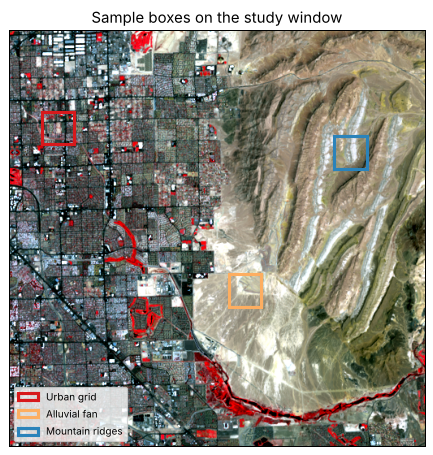

In [14]:
# three 40 x 40 pixel sample boxes (rows, columns) in the study window
BOXES = {"Urban grid": (slice(100, 140), slice(40, 80)),
         "Alluvial fan": (slice(300, 340), slice(270, 310)),  # gravel slopes east of the city
         "Mountain ridges": (slice(130, 170), slice(400, 440))}  # rugged terrain
# one colour per box
COLORS = {"Urban grid": "#d7191c", "Alluvial fan": "#fdae61", "Mountain ridges": "#2b83ba"}

fig, ax = plt.subplots(figsize=(6, 6))  # one panel
# colour infrared background
rs.viz.plot_rgb(sub, "false_color", ax=ax, title="Sample boxes on the study window")
for name, (ys, xs) in BOXES.items():  # draw each box
    # x = column start, y = row start, then width and height
    ax.add_patch(Rectangle((xs.start, ys.start), xs.stop - xs.start, ys.stop - ys.start,
                           # outline only, labelled for the legend
                           fill=False, ec=COLORS[name], lw=2.5, label=name))
ax.legend(loc="lower left", fontsize=8); ax.set_xticks([]); ax.set_yticks([])  # legend, no ticks
plt.show()  # draw

In [15]:
from sklearn.cluster import KMeans  # k-means clustering
from sklearn.preprocessing import StandardScaler  # standardise features to mean 0, std 1
from scipy.ndimage import generic_filter  # moving-window filter for the speckle measure

def box_means(ds):  # average feature values per sample box
    """Mean of every variable of `ds` inside each sample box."""
    # rows = features, columns = boxes
    return pd.DataFrame({name: {v: float(ds[v].isel(y=ys, x=xs).mean()) for v in ds.data_vars}
                         for name, (ys, xs) in BOXES.items()})

def plot_signatures(sig, title):  # compare the boxes feature by feature
    """Bar chart of box means, min-max scaled per feature across the three boxes."""
    # scale each feature to 0-1 across the three boxes
    norm = sig.sub(sig.min(axis=1), axis=0).div(sig.max(axis=1) - sig.min(axis=1), axis=0)
    fig, ax = plt.subplots(figsize=(max(7, 0.75 * len(norm)), 4.5))  # width grows with the number of features
    x = np.arange(len(norm))  # one group of bars per feature
    for k, name in enumerate(norm.columns):  # one bar per box, shifted sideways
        ax.bar(x + (k - 1) * 0.27, norm[name], width=0.27, color=COLORS[name], label=name)  # draw the bars
    ax.set_xticks(x, norm.index, rotation=45, ha="right")  # feature names, rotated
    ax.set(ylabel="Relative value (0 = lowest box, 1 = highest)", title=title)  # labels
    ax.legend(); plt.tight_layout(); plt.show()  # legend and draw

def kmeans_map(ds, k=5, n_fit=40000, seed=0):  # unsupervised map from a set of layers
    """Standardize the layers, fit k-means on a random pixel sample and label every pixel."""
    df = ds.to_dataframe(dim_order=["y", "x"])[list(ds.data_vars)]  # pixels as rows, layers as columns
    ok = df.notna().all(axis=1).values  # pixels without missing values
    X = StandardScaler().fit_transform(df[ok].values)  # standardise so every layer weighs the same
    rng = np.random.default_rng(seed)  # random sample generator
    # fit on at most 40,000 random pixels (faster)
    km = KMeans(k, n_init=10, random_state=seed).fit(X[rng.choice(len(X), min(n_fit, len(X)), replace=False)])
    lab = np.full(ok.size, np.nan); lab[ok] = km.predict(X)  # label all valid pixels; others stay NaN
    # labels back on the image grid
    return xr.DataArray(lab.reshape(ds.sizes["y"], ds.sizes["x"]), coords={"y": ds.y, "x": ds.x}, dims=("y", "x"))

def speckle(lab):  # how noisy a cluster map is
    """Share of pixels whose label differs from the majority label of their 3 x 3 neighbourhood."""
    a = np.nan_to_num(lab.values, nan=-1).astype(int)  # NaN -> -1 so the labels are integers
    # majority label in each 3 x 3 window
    mode = generic_filter(a, lambda v: np.bincount(v.astype(int) + 1).argmax() - 1, size=3)
    return float((a != mode).mean())  # share of pixels that differ from their neighbourhood majority

def box_purity(lab):  # how uniform each box is in a cluster map
    """Share of each box's pixels that fall in the box's most common cluster."""
    out = {}  # one value per box
    for name, (ys, xs) in BOXES.items():  # loop over the boxes
        v = lab.isel(y=ys, x=xs).values.ravel()  # labels inside the box
        v = v[np.isfinite(v)].astype(int)  # drop missing labels
        out[name] = np.bincount(v).max() / v.size  # share of the most common label
    return out  # dictionary box -> purity

# Spectral layers used as the baseline in every notebook: the four bands and NDVI.
# normalised difference vegetation index
ndvi = ((sub["nir"] - sub["red"]) / (sub["nir"] + sub["red"])).rename("NDVI")
spectral = xr.Dataset({**{b: sub[b] for b in BANDS}, "NDVI": ndvi})  # four bands plus NDVI

In [16]:
mb_feats = xr.Dataset({  # the model-based layers of this notebook
    "log10 MRF energy (4)": np.log10(mrf4), "MRF 8/4 ratio": mrf8 / mrf4,  # MRF energy and the 8/4 ratio
    "Fractal dim. (32)": fd, "Fractal dim. (64)": fd64,  # fractal dimension at two tile sizes
    "AR rho (9)": ar["rho"], "AR residual (9)": ar["residual"],  # AR parameters, 9 x 9
    "AR rho (15)": ar15["rho"], "AR residual (15)": ar15["residual"],  # AR parameters, 15 x 15
})
sig = box_means(mb_feats)  # mean of each feature in each box
# show the table
sig.round(4)

,Urban grid,Alluvial fan,Mountain ridges
log10 MRF energy (4),-2.5912,-3.4451,-3.4342
MRF 8/4 ratio,1.3333,1.2809,1.3177
Fractal dim. (32),2.2054,2.1800,2.1465
Fractal dim. (64),2.2581,2.1536,2.1745
AR rho (9),1.1700,1.1641,1.1155
AR residual (9),0.2251,0.2214,0.1522
AR rho (15),1.1472,1.1302,1.0904
AR residual (15),0.1791,0.1668,0.1004


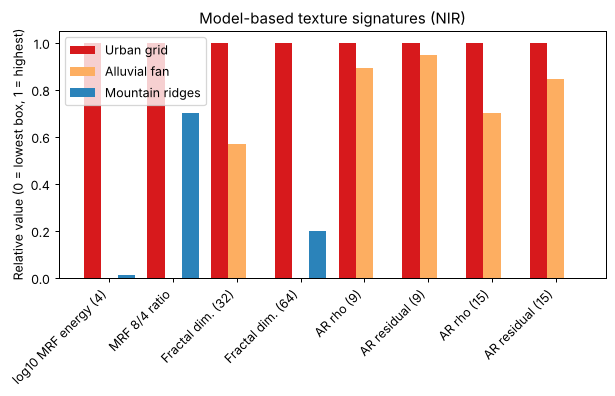

In [17]:
plot_signatures(sig, "Model-based texture signatures (NIR)")  # bar chart of the box signatures

MRF energy and the 64 × 64 fractal dimension are highest in the city. The ridges have the lowest AR ρ and
residual (the most coherent surface); the fan and the city have similar AR values at 9 × 9.


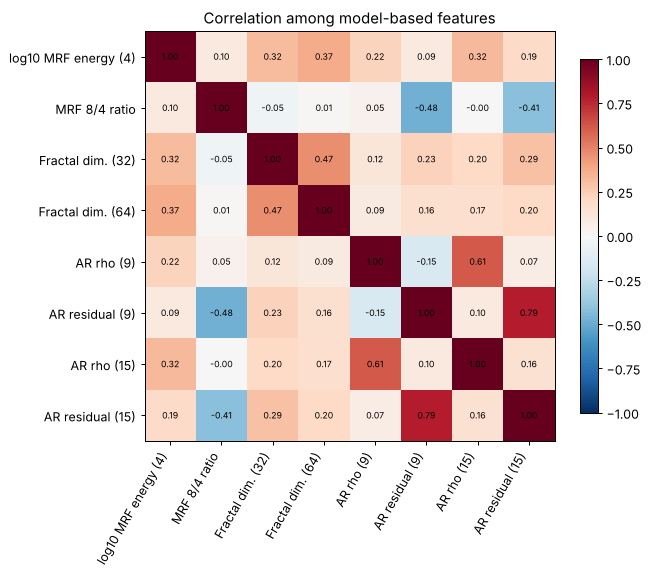

In [18]:
mdf = mb_feats.to_dataframe()[list(mb_feats.data_vars)].dropna()  # pixels as rows, features as columns
mc = mdf.corr()  # Pearson correlation
names = list(mb_feats.data_vars)  # feature names for the axes
fig, ax = plt.subplots(figsize=(7.5, 6.5))  # one panel
im = ax.imshow(mc, cmap="RdBu_r", vmin=-1, vmax=1)  # the correlation matrix
# labels on both axes
ax.set_xticks(range(len(names)), names, rotation=60, ha="right"); ax.set_yticks(range(len(names)), names)
for i in range(len(names)):  # write each value in its cell
    for j in range(len(names)):  # columns
        ax.text(j, i, f"{mc.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)  # two decimals
plt.colorbar(im, shrink=0.8); ax.set_title("Correlation among model-based features")  # colour bar and title
plt.tight_layout(); plt.show()  # arrange and draw

The model-based features are much less redundant than the statistical or transform features. The two AR
residuals (r = 0.79) and the two ρ values (0.61) repeat each other across windows, and the two fractal
dimensions agree only moderately (0.47). Across families, correlations are weak (|r| ≤ 0.48).


### Does this family add information? A clustering test

Texture is useful only if it carries information that the spectral bands do not. We run k-means with
5 clusters on (a) the four bands and NDVI only and (b) the same spectral layers plus this notebook's
texture features, all standardized. Two numbers summarize the maps:

- **Speckle**: the share of pixels whose cluster differs from the majority of their 3 × 3
  neighbourhood (lower = more spatially coherent).
- **Purity**: the share of pixels in each sample box that fall in that box's most common cluster
  (higher = the surface is mapped as one unit).


In [19]:
def compare_clusterings(texture_ds, label):  # clustering with and without the texture layers
    """k-means on spectral layers only vs spectral + texture layers; maps, speckle and box purity."""
    k_spec = kmeans_map(spectral)  # five spectral layers
    k_both = kmeans_map(xr.merge([spectral, texture_ds], compat="override"))  # spectral plus texture layers
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))  # three panels
    rs.viz.plot_rgb(sub, "false_color", ax=axes[0], title="Colour infrared")  # reference image
    for ax, lab, t in zip(axes[1:], [k_spec, k_both],  # the two cluster maps with their titles
                          ["k-means, spectral only (5 layers)",
                           f"k-means, spectral + {label} ({5 + len(texture_ds.data_vars)} layers)"]):
        ax.imshow(lab, cmap="Set2", interpolation="nearest")  # one colour per cluster
        ax.set_title(f"{t}\nspeckle = {speckle(lab):.1%}")  # title with the speckle share
    for a in axes:  # no pixel ticks
        a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.show()  # arrange and draw
    return pd.DataFrame({"spectral only": box_purity(k_spec),  # box purity of both maps, as percentages
                         # format each value as a percentage
                         f"spectral + {label}": box_purity(k_both)}).map(lambda v: f"{v:.0%}")

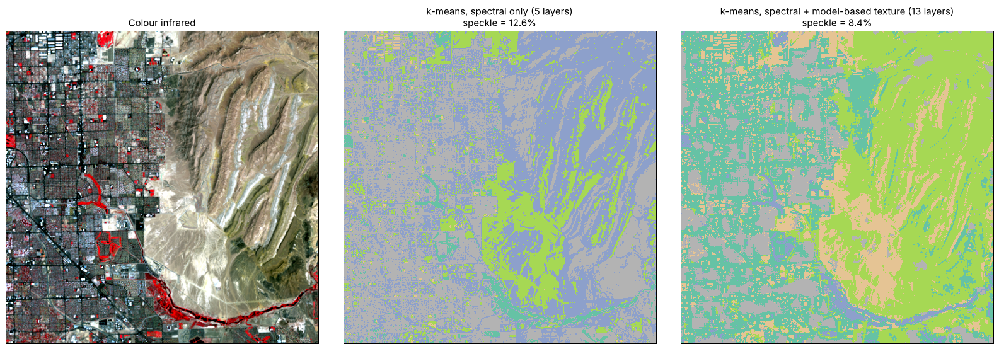

,spectral only,spectral + model-based texture
Urban grid,53%,76%
Alluvial fan,58%,48%
Mountain ridges,66%,78%


In [20]:
compare_clusterings(mb_feats, "model-based texture")  # maps, speckle and box purity

Model-based texture reduces speckle from 12.6% to 8.4% and raises purity in the city (53% to 76%) and
on the ridges (66% to 78%). The fan, however, is split between two clusters (purity 48%): the AR residual
and fractal dimension vary across the fan's gullies and roads. These layers work best combined with the
roughness measures of notebook 09_07_01.


In [21]:
OUT = Path("outputs") / "texture"  # output folder for texture rasters
OUT.mkdir(parents=True, exist_ok=True)  # create it if needed
# Dataset -> one multi-band GeoTIFF (one band per feature)
mb_feats.to_array("feature").astype("float32").rio.write_crs(ls.rio.crs).rio.to_raster(OUT / "nir_model_texture.tif")
with rasterio.open(OUT / "nir_model_texture.tif") as src:  # read the file back to check it
    # number of bands, size and CRS
    print(f"nir_model_texture.tif: {src.count} bands, {src.width} x {src.height}, {src.crs}")

nir_model_texture.tif: 8 bands, 512 x 512, EPSG:32611


## Summary and exercises

**Key points**

- Model-based texture fits a spatial stochastic model and uses its parameters as features.
- MRF clique energy measures how strongly neighbours disagree under a smoothness prior; white noise of
  unit variance has energy 2, correlated surfaces much less.
- Fractal dimension measures the roughness of the intensity surface. Box-counting estimates are biased
  but rank surfaces correctly, so use D as a relative measure.
- The AR coefficient ρ measures spatial coherence and the residual share the variation the neighbours
  cannot explain. ρ slightly above 1 is expected for partly correlated images.
- MRF energy and the AR model run on full scenes in about a second, which makes them practical
  predictors for large-area mapping.

**`geolattice.rsense` functions used:** `rs.read`, `rs.optical.scale`, `rs.viz.plot_rgb`, `rs.viz.plot_raster`,
`tx.mrf_texture_energy`, `tx.fractal_dimension`, `tx.autoregressive_texture`.

**Exercises**

1. Use more box sizes (2, 4, 8, 16, 32) on 64 × 64 tiles for the synthetic fBm surfaces. Does the
   estimate get closer to the theoretical D?
2. Compute MRF energy on NDVI. Which surfaces have the most "texture" in vegetation rather than in
   brightness?
3. Extend the AR model to separate horizontal and vertical neighbours (two coefficients). Do the two
   coefficients differ on the ridges?
4. Apply the three measures to a Sentinel-1 VV backscatter image in dB. How does speckle affect each
   one?
5. Compare the fractal dimension map with a slope map from a DEM of the same area.

**References**

- Cross, G.R. and Jain, A.K. (1983). Markov random field texture models. *IEEE TPAMI*, 5(1), 25-39.
- Geman, S. and Geman, D. (1984). Stochastic relaxation, Gibbs distributions, and the Bayesian
  restoration of images. *IEEE TPAMI*, 6(6), 721-741.
- Kashyap, R.L. and Chellappa, R. (1983). Estimation and choice of neighbors in spatial-interaction
  models of images. *IEEE Transactions on Information Theory*, 29(1), 60-72.
- Mandelbrot, B.B. (1982). *The Fractal Geometry of Nature*. W.H. Freeman.
- Mao, J. and Jain, A.K. (1992). Texture classification and segmentation using multiresolution
  simultaneous autoregressive models. *Pattern Recognition*, 25(2), 173-188.
- Pentland, A.P. (1984). Fractal-based description of natural scenes. *IEEE TPAMI*, 6(6), 661-674.
- Sarkar, N. and Chaudhuri, B.B. (1994). An efficient differential box-counting approach to compute
  fractal dimension of image. *IEEE Transactions on Systems, Man, and Cybernetics*, 24(1), 115-121.

**Previous:** [Local pattern-based texture](09_07_03_texture_analysis_of_landsat_imagery_local_pattern_based_methods_lbp.ipynb) ·
**Next:** [Deep-learning-based texture](09_07_05_texture_analysis_of_landsat_imagery_deep_learning_based_methods.ipynb).
